In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

In [3]:
X_train = pd.read_csv("../data/preparation_données/X_train.csv", index_col=0)
X_test = pd.read_csv("../data/preparation_données/X_test.csv", index_col=0)
y_train = pd.read_csv("../data/preparation_données/y_train.csv", index_col=0).squeeze()
y_test = pd.read_csv("../data/preparation_données/y_test.csv", index_col=0).squeeze()

print(X_train.shape, X_test.shape)        # (4256, 10) (1064, 10)
print("Proportion de bons vins :", round(y_train.mean(), 3), round(y_test.mean(), 3))

(4256, 10) (1064, 10)
Proportion de bons vins : 0.19 0.19


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [5]:
modeles = {
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Arbre de décision": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Naive Bayes": GaussianNB(),
    "SVM": make_pipeline(StandardScaler(), SVC(class_weight="balanced", probability=True, random_state=42)),
}

In [6]:
metriques = ["accuracy", "precision", "recall", "f1", "roc_auc"]

lignes = []
for nom, modele in modeles.items():
    res = cross_validate(modele, X_train, y_train, cv=cv,
                         scoring=metriques, return_train_score=True)
    ligne = {"modèle": nom}
    for m in metriques:
        ligne[m] = res[f"test_{m}"].mean()
    ligne["F1 écart-type"] = res["test_f1"].std()   # stabilité entre les plis
    ligne["F1 train"] = res["train_f1"].mean()      # pour le diagnostic biais/variance
    lignes.append(ligne)

evaluation = pd.DataFrame(lignes).set_index("modèle")
evaluation.round(3)

/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn

,accuracy,precision,recall,f1,roc_auc,F1 écart-type,F1 train
modèle,,,,,,,
Régression logistique,0.739,0.404,0.786,0.533,0.831,0.019,0.536
k-NN,0.817,0.524,0.374,0.436,0.783,0.038,0.621
Arbre de décision,0.788,0.437,0.408,0.421,0.642,0.016,1.000
Naive Bayes,0.760,0.412,0.625,0.497,0.785,0.019,0.502
SVM,0.741,0.408,0.809,0.543,0.841,0.014,0.572


In [7]:
from sklearn.base import clone
from sklearn.metrics import f1_score

scores = []
for i, (idx_train, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    m = clone(modeles["Régression logistique"])       # copie neuve, pas encore entraînée
    m.fit(X_train.iloc[idx_train], y_train.iloc[idx_train])    # ← ENTRAÎNEMENT
    pred = m.predict(X_train.iloc[idx_val])                    # prédictions sur le pli de validation
    s = f1_score(y_train.iloc[idx_val], pred)
    print(f"Pli {i} : entraîné sur {len(idx_train)} vins, F1 = {s:.3f} sur {len(idx_val)} vins")
    scores.append(s)

print("F1 moyen :", round(np.mean(scores), 3))

Pli 1 : entraîné sur 3404 vins, F1 = 0.510 sur 852 vins
Pli 2 : entraîné sur 3405 vins, F1 = 0.532 sur 851 vins
Pli 3 : entraîné sur 3405 vins, F1 = 0.544 sur 851 vins
Pli 4 : entraîné sur 3405 vins, F1 = 0.516 sur 851 vins
Pli 5 : entraîné sur 3405 vins, F1 = 0.564 sur 851 vins
F1 moyen : 0.533


/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn

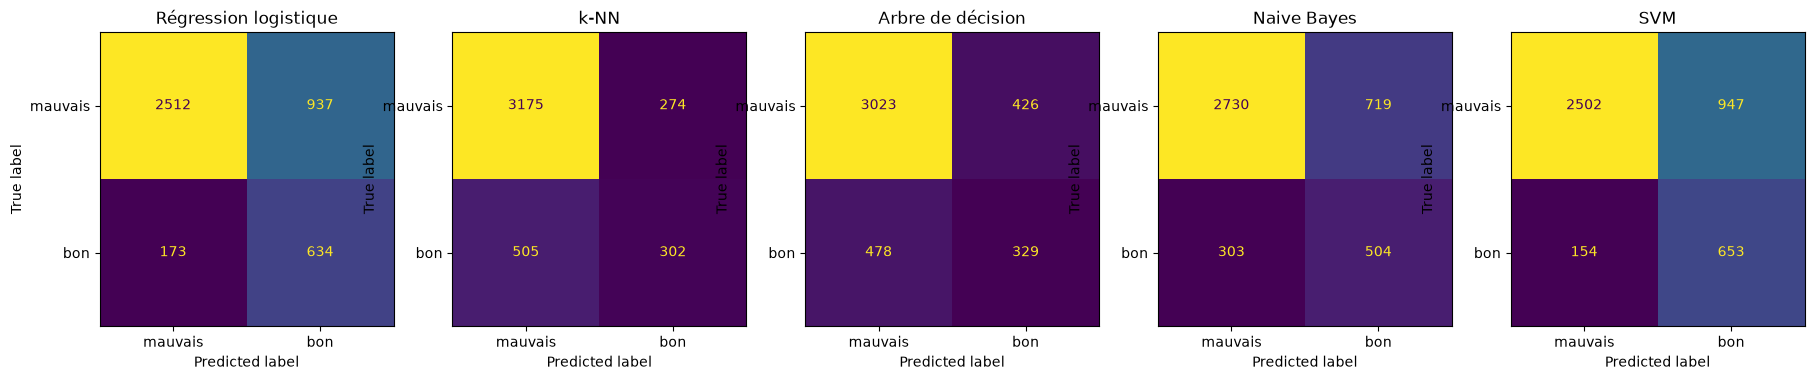

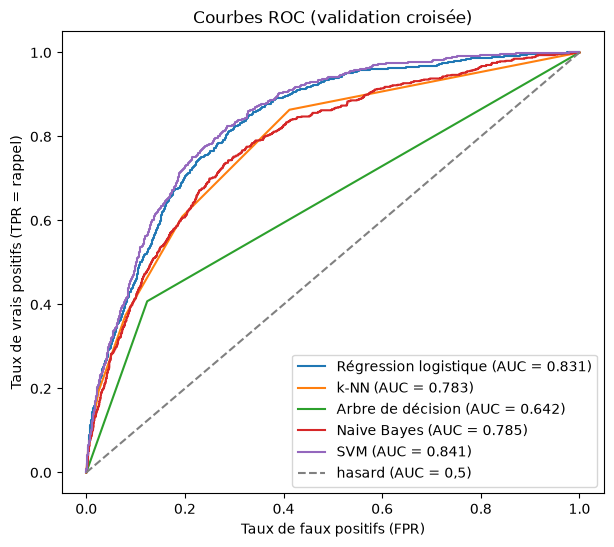

In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
plt.figure(2, figsize=(7, 6))   # figure séparée pour les courbes ROC

for ax, (nom, modele) in zip(axes, modeles.items()):
    # 1) classes prédites hors-pli → matrice de confusion
    pred = cross_val_predict(modele, X_train, y_train, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y_train, pred, ax=ax, colorbar=False,
                                            display_labels=["mauvais", "bon"])
    ax.set_title(nom)

    # 2) scores hors-pli → courbe ROC
    methode = "decision_function" if hasattr(modele, "decision_function") else "predict_proba"
    score = cross_val_predict(modele, X_train, y_train, cv=cv, method=methode)
    if score.ndim == 2:          # predict_proba renvoie 2 colonnes : on garde la proba de « bon »
        score = score[:, 1]
    fpr, tpr, _ = roc_curve(y_train, score)
    plt.figure(2)
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_train, score):.3f})")

plt.figure(2)
plt.plot([0, 1], [0, 1], "--", color="gray", label="hasard (AUC = 0,5)")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR = rappel)")
plt.title("Courbes ROC (validation croisée)")
plt.legend()
plt.show()

In [9]:
from sklearn.model_selection import GridSearchCV
import time

grilles = {
    "Régression logistique": {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    "k-NN": {"kneighborsclassifier__n_neighbors": [3, 5, 7, 11, 15, 21, 31],
             "kneighborsclassifier__weights": ["uniform", "distance"]},
    "Arbre de décision": {"max_depth": [3, 5, 7, 10, 15, None],
                          "min_samples_leaf": [1, 5, 10, 20, 50],
                          "criterion": ["gini", "entropy"]},
    "Naive Bayes": {"var_smoothing": [1e-12, 1e-9, 1e-6, 1e-3]},
    "SVM": {"svc__C": [0.1, 1, 10],
            "svc__kernel": ["linear", "rbf"],
            "svc__gamma": ["scale", 0.1, 1]},
}

resultats_grid = {}
for nom, grille in grilles.items():
    debut = time.time()
    recherche = GridSearchCV(modeles[nom], grille, cv=cv, scoring="f1",
                             return_train_score=True, n_jobs=-1)
    recherche.fit(X_train, y_train)
    resultats_grid[nom] = recherche
    print(f"{nom:<22} F1 = {recherche.best_score_:.3f}  ({time.time() - debut:.1f} s)  {recherche.best_params_}")

Régression logistique  F1 = 0.537  (2.0 s)  {'logisticregression__C': 0.01}
k-NN                   F1 = 0.466  (1.1 s)  {'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'distance'}
Arbre de décision      F1 = 0.513  (0.8 s)  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 50}
Naive Bayes            F1 = 0.497  (0.0 s)  {'var_smoothing': 1e-09}


/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn

SVM                    F1 = 0.543  (19.7 s)  {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}


In [10]:
pd.set_option("display.max_colwidth", None)   # afficher les paramètres en entier

recap = pd.DataFrame({
    nom: {
        "F1 avant": evaluation.loc[nom, "f1"],
        "F1 après": r.best_score_,
        "F1 train": r.cv_results_["mean_train_score"][r.best_index_],
        "meilleurs paramètres": r.best_params_,
    }
    for nom, r in resultats_grid.items()
}).T
recap

,F1 avant,F1 après,F1 train,meilleurs paramètres
Régression logistique,0.533307,0.536846,0.53905,{'logisticregression__C': 0.01}
k-NN,0.43635,0.465681,1.0,"{'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'distance'}"
Arbre de décision,0.420735,0.5127,0.56329,"{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 50}"
Naive Bayes,0.496549,0.496549,0.502257,{'var_smoothing': 1e-09}
SVM,0.542662,0.542662,0.572368,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}"


In [11]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

distributions = {
    "Régression logistique": {"logisticregression__C": loguniform(1e-4, 1e2)},
    "k-NN": {"kneighborsclassifier__n_neighbors": randint(1, 50),
             "kneighborsclassifier__weights": ["uniform", "distance"]},
    "Arbre de décision": {"max_depth": randint(2, 20),
                          "min_samples_leaf": randint(1, 100),
                          "criterion": ["gini", "entropy"]},
    "Naive Bayes": {"var_smoothing": loguniform(1e-12, 1e-1)},
    "SVM": {"svc__C": loguniform(1e-2, 1e2),
            "svc__gamma": loguniform(1e-3, 1e1),
            "svc__kernel": ["rbf"]},
}

resultats_random = {}
for nom, distrib in distributions.items():
    debut = time.time()
    recherche = RandomizedSearchCV(modeles[nom], distrib, n_iter=20, cv=cv, scoring="f1",
                                   return_train_score=True, random_state=42, n_jobs=-1)
    recherche.fit(X_train, y_train)
    resultats_random[nom] = recherche
    print(f"{nom:<22} F1 = {recherche.best_score_:.3f}  ({time.time() - debut:.1f} s)")

Régression logistique  F1 = 0.539  (2.1 s)
k-NN                   F1 = 0.460  (1.7 s)
Arbre de décision      F1 = 0.509  (0.3 s)
Naive Bayes            F1 = 0.503  (0.2 s)


/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/yukiry/Documents/efrei/Ing 2/Machine learning 1/wine-quality/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn

SVM                    F1 = 0.544  (21.0 s)


In [12]:
comparaison_recherche = pd.DataFrame({
    nom: {
        "F1 Grid": resultats_grid[nom].best_score_,
        "F1 Random": resultats_random[nom].best_score_,
        "nb combinaisons Grid": len(resultats_grid[nom].cv_results_["params"]),
        "nb combinaisons Random": len(resultats_random[nom].cv_results_["params"]),
        "paramètres Random": resultats_random[nom].best_params_,
    }
    for nom in resultats_grid
}).T
comparaison_recherche

,F1 Grid,F1 Random,nb combinaisons Grid,nb combinaisons Random,paramètres Random
Régression logistique,0.536846,0.538787,5,20,{'logisticregression__C': 0.039054412752107935}
k-NN,0.465681,0.460049,14,20,"{'kneighborsclassifier__n_neighbors': 12, 'kneighborsclassifier__weights': 'distance'}"
Arbre de décision,0.5127,0.509291,60,20,"{'criterion': 'gini', 'max_depth': 13, 'min_samples_leaf': 55}"
Naive Bayes,0.496549,0.503135,4,20,{'var_smoothing': 5.6415079575079687e-08}
SVM,0.542662,0.544008,18,20,"{'svc__C': 5.456725485601478, 'svc__gamma': 0.057624872164786026, 'svc__kernel': 'rbf'}"


## Choix du modèle final : la régression logistique

Après optimisation, deux modèles se détachent : la **régression logistique** et le **SVM à noyau RBF**.

| Critère (validation croisée 5-fold) | Régression logistique | SVM (RBF) |
|---|---|---|
| F1 | ≈ 0,54 | ≈ 0,54 |
| AUC | 0,83 | 0,84 |
| Écart F1 train − validation | 0,003 | 0,03 |

Le SVM obtient des scores légèrement supérieurs, mais l'écart de F1 (≈ 0,005) est bien plus faible
que la variation du score d'un pli à l'autre (écart-type ≈ 0,015). Les deux modèles ont donc des
**performances statistiquement équivalentes**.

À performances égales, nous retenons la **régression logistique** pour trois raisons :

- **Simplicité (principe de parcimonie)** : c'est un modèle linéaire, moins complexe que le SVM.
  Son écart quasi nul entre score d'entraînement et score de validation montre qu'il ne
  sur-apprend pas.
- **Interprétabilité** : ses coefficients indiquent directement l'effet de chaque variable sur la
  qualité (par exemple, l'alcool l'augmente, l'acidité volatile la diminue). Le SVM à noyau RBF
  est une « boîte noire ».
- **Probabilités et rapidité** : elle fournit directement une probabilité d'être un bon vin
  (fonction sigmoïde), ce qui permet d'ajuster le seuil de décision selon l'usage, et elle
  s'entraîne en une fraction de seconde.

Le choix est fait uniquement à partir de la validation croisée : le jeu de test n'est utilisé
qu'une seule fois, pour l'évaluation finale de ce modèle.

In [13]:
modele_final = resultats_random["Régression logistique"].best_estimator_

              precision    recall  f1-score   support

     mauvais      0.936     0.715     0.811       862
         bon      0.394     0.792     0.526       202

    accuracy                          0.729      1064
   macro avg      0.665     0.753     0.668      1064
weighted avg      0.833     0.729     0.757      1064

F1 validation croisée : 0.539
F1 test               : 0.526


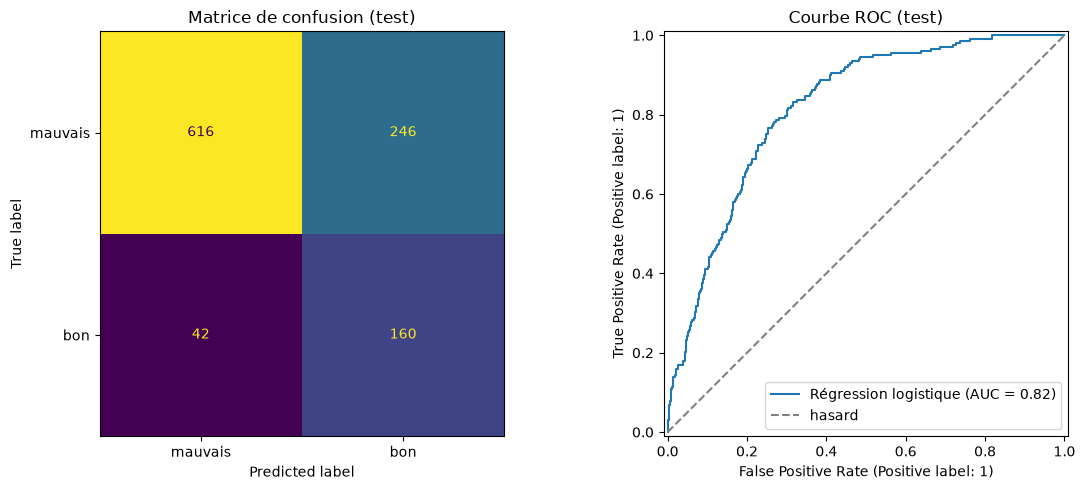

In [14]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay, f1_score

modele_final = resultats_random["Régression logistique"].best_estimator_   # déjà entraîné sur tout X_train

pred_test = modele_final.predict(X_test)
print(classification_report(y_test, pred_test, target_names=["mauvais", "bon"], digits=3))

print("F1 validation croisée :", round(resultats_random["Régression logistique"].best_score_, 3))
print("F1 test               :", round(f1_score(y_test, pred_test), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=axes[0],
                                        display_labels=["mauvais", "bon"], colorbar=False)
axes[0].set_title("Matrice de confusion (test)")
RocCurveDisplay.from_estimator(modele_final, X_test, y_test, ax=axes[1], name="Régression logistique")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="hasard")
axes[1].set_title("Courbe ROC (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

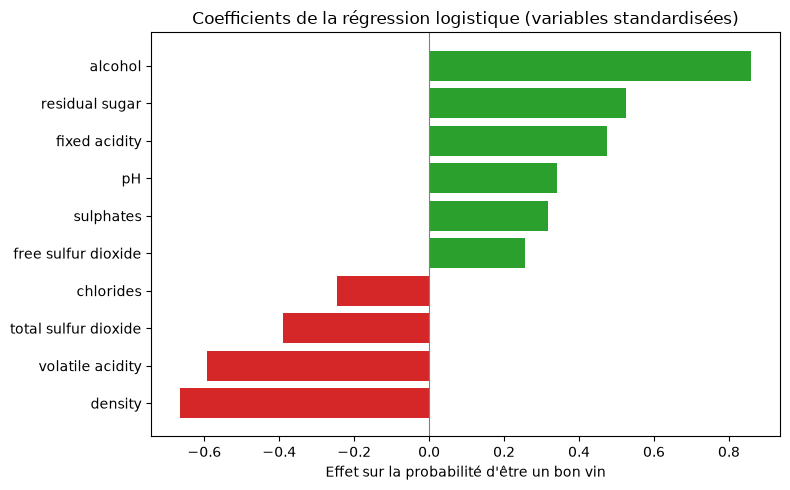

In [15]:
coefs_final = pd.Series(modele_final[-1].coef_[0], index=X_train.columns).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(coefs_final.index, coefs_final.values,
         color=["tab:red" if v < 0 else "tab:green" for v in coefs_final.values])
plt.axvline(0, color="gray", linewidth=0.8)
plt.title("Coefficients de la régression logistique (variables standardisées)")
plt.xlabel("Effet sur la probabilité d'être un bon vin")
plt.tight_layout()
plt.show()

In [16]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)
joblib.dump(modele_final, "../models/modele_final.joblib")

['../models/modele_final.joblib']